First five rows of dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


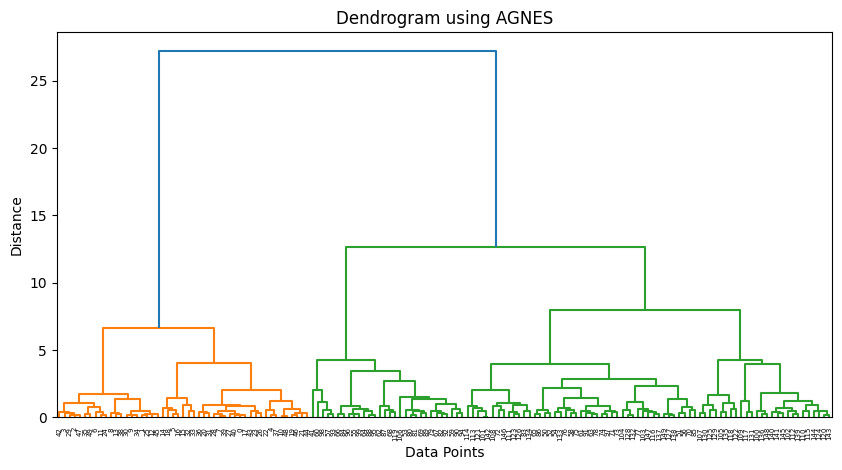


AGNES Cluster Labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 2 1 1 1 1 1 1 1 1 0 0 0 2 0 2 0 2 0 2 2 0 2 0 2 0 2 2 2 2 0 0 0 0
 0 0 0 0 0 2 2 2 2 0 2 0 0 2 2 2 2 0 2 2 2 2 2 0 2 2 0 0 0 0 0 0 2 0 0 0 0
 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]

AGNES Silhouette Score: 0.4466890410285909

DIANA Cluster Labels:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 1 1 1 2 1 1 1 1 1 1 1 1 2 1 1 1 1 2 1 1 1
 1 2 2 2 1 1 1 1 1 1 1 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 2 2 2 2 1 2 1 2 2
 1 2 1 1 2 2 2 2 1 2 1 2 1 2 2 1 1 2 2 2 2 2 1 1 2 2 2 1 2 2 2 1 2 2 2 1 2
 2 1]

DIANA Silhouette Score: 0.4630420362927048


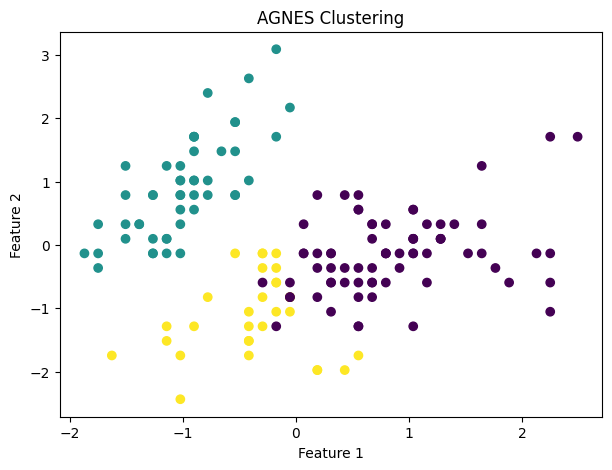

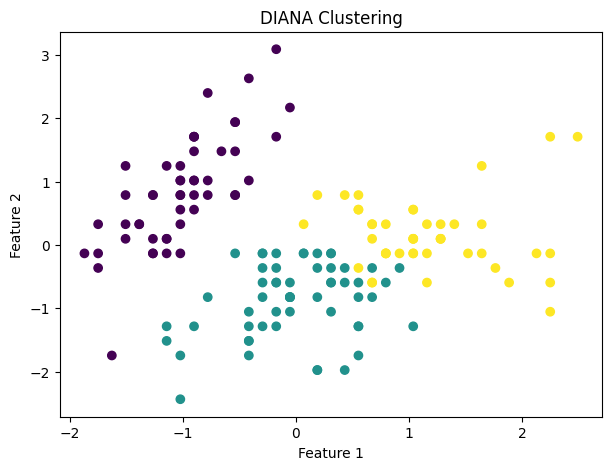


Comparison of AGNES and DIANA:
  Method  Number of Clusters  Silhouette Score
0  AGNES                   3          0.446689
1  DIANA                   3          0.463042


In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform


iris = load_iris()
X = iris.data

df = pd.DataFrame(X, columns=iris.feature_names)

print("First five rows of dataset:")
print(df.head())

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


linked = linkage(X_scaled, method='ward')

plt.figure(figsize=(10, 5))
dendrogram(linked)
plt.title("Dendrogram using AGNES")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()


agnes = AgglomerativeClustering(n_clusters=3, linkage='ward')
agnes_labels = agnes.fit_predict(X_scaled)

df["AGNES Cluster"] = agnes_labels


agnes_score = silhouette_score(X_scaled, agnes_labels)

print("\nAGNES Cluster Labels:")
print(agnes_labels)

print("\nAGNES Silhouette Score:", agnes_score)



def diana_clustering(X, n_clusters=3):
    """
    Simple DIANA clustering implementation.
    Starts with one cluster and repeatedly splits the cluster
    having the largest diameter.
    """

    clusters = [list(range(len(X)))]

    while len(clusters) < n_clusters:

        max_diameter = -1
        cluster_to_split_index = None

        for i, cluster in enumerate(clusters):
            if len(cluster) <= 1:
                continue

            distances = squareform(pdist(X[cluster]))
            diameter = np.max(distances)

            if diameter > max_diameter:
                max_diameter = diameter
                cluster_to_split_index = i

        if cluster_to_split_index is None:
            break

        cluster_to_split = clusters.pop(cluster_to_split_index)

        sub_X = X[cluster_to_split]
        distances = squareform(pdist(sub_X))


        avg_distances = np.mean(distances, axis=1)
        splinter_index = np.argmax(avg_distances)

        splinter_group = [cluster_to_split[splinter_index]]
        remaining_group = [
            point for idx, point in enumerate(cluster_to_split)
            if idx != splinter_index
        ]

        changed = True

        while changed:
            changed = False

            for point in remaining_group[:]:
                dist_to_splinter = np.mean([
                    np.linalg.norm(X[point] - X[s])
                    for s in splinter_group
                ])

                dist_to_remaining = np.mean([
                    np.linalg.norm(X[point] - X[r])
                    for r in remaining_group
                    if r != point
                ]) if len(remaining_group) > 1 else 0

                if dist_to_splinter < dist_to_remaining:
                    splinter_group.append(point)
                    remaining_group.remove(point)
                    changed = True

        clusters.append(remaining_group)
        clusters.append(splinter_group)

    labels = np.zeros(len(X), dtype=int)

    for cluster_id, cluster in enumerate(clusters):
        for point in cluster:
            labels[point] = cluster_id

    return labels


diana_labels = diana_clustering(X_scaled, n_clusters=3)

df["DIANA Cluster"] = diana_labels

diana_score = silhouette_score(X_scaled, diana_labels)

print("\nDIANA Cluster Labels:")
print(diana_labels)

print("\nDIANA Silhouette Score:", diana_score)


plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=agnes_labels)
plt.title("AGNES Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=diana_labels)
plt.title("DIANA Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


comparison = pd.DataFrame({
    "Method": ["AGNES", "DIANA"],
    "Number of Clusters": [
        len(np.unique(agnes_labels)),
        len(np.unique(diana_labels))
    ],
    "Silhouette Score": [agnes_score, diana_score]
})

print("\nComparison of AGNES and DIANA:")
print(comparison)
